# Convolutional AE con Keras

https://blog.keras.io/building-autoencoders-in-keras.html

In [51]:
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

import matplotlib.pyplot as plt

In [53]:
def conv_block(inputs, filters, pool = True):
    ''' Define a convolutional block of the encoder.

    Arguments:
        - inputs (tf tensor): Input tensor
        - filters (int): Number of filters
        - pool (bool): Do the MaxPooling or not -- True

    Returns:
        - x (tf tensor): Output tensor before the MaxPooling
        - p (tf tensor): Output tensor after the MaxPooling '''

    x = tf.keras.layers.Conv2D(filters, 3, padding = "same")(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    x = tf.keras.layers.Conv2D(filters, 3, padding = "same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    if pool == True:
        p = tf.keras.layers.MaxPool2D((2, 2))(x)
        return x, p
    else:
        return x


def build_unet(shape, num_classes):
    ''' Build an UNET form model with GDN.

    Arguments:
        - shape ((int, int, int)): Shape of the input tensor
        - num_classes (int): Number of classes

    Returns:
        - model (tf model): Model built '''

    inputs = tf.keras.Input(shape)

    # Encoder
    x1, p1 = conv_block(inputs, 16, pool = True)
    x2, p2 = conv_block(p1, 32, pool = True)
    x3, p3 = conv_block(p2, 64, pool = True)
    x4, p4 = conv_block(p3, 128, pool = True)

    b1 = conv_block(p4, 256, pool = False)

    # Decoder
    u1 = tf.keras.layers.Conv2DTranspose(256, kernel_size = (3, 3), strides = (2, 2), padding = 'same')(b1)
    c1 = tf.keras.layers.Concatenate()([u1, x4])
    x5 = conv_block(c1, 128, pool = False)

    u2 = tf.keras.layers.Conv2DTranspose(128, kernel_size = (3, 3), strides = (2, 2), padding = 'same')(x5)
    c2 = tf.keras.layers.Concatenate()([u2, x3])
    x6 = conv_block(c2, 64, pool = False)

    u3 = tf.keras.layers.Conv2DTranspose(64, kernel_size = (3, 3), strides = (2, 2), padding = 'same')(x6)
    c3 = tf.keras.layers.Concatenate()([u3, x2])
    x7 = conv_block(c3, 32, pool = False)

    u4 = tf.keras.layers.Conv2DTranspose(32, kernel_size = (3, 3), strides = (2, 2), padding = 'same')(x7)
    c4 = tf.keras.layers.Concatenate()([u4, x1])
    x8 = conv_block(c4, 16, pool = False)

    # Output
    output = tf.keras.layers.Conv2D(num_classes, 1, padding = 'same', activation = 'relu')(x8)
    # Para calsificación
    #output = tf.keras.layers.Conv2D(num_classes, 1, padding = 'same', activation = 'softmax')(x8)

    return tf.keras.Model(inputs, output)

In [54]:
SH = [32,32,3]
CH_salida = 3
model = build_unet(SH,CH_salida)

In [55]:
model.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_3 (InputLayer)        [(None, 32, 32, 3)]          0         []                            
                                                                                                  
 conv2d_38 (Conv2D)          (None, 32, 32, 16)           448       ['input_3[0][0]']             
                                                                                                  
 batch_normalization_36 (Ba  (None, 32, 32, 16)           64        ['conv2d_38[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_36 (Activation)  (None, 32, 32, 16)           0         ['batch_normalization_36

In [57]:
opt = Adam(learning_rate=0.001)
model.compile(optimizer=opt, loss='mse')

In [58]:
# DATOS
from keras.datasets import cifar10
import numpy as np

(x_train, _), (x_test, _) = cifar10.load_data()

x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.
x_train = np.reshape(x_train, (len(x_train), 32, 32, 3))
x_test = np.reshape(x_test, (len(x_test), 32, 32, 3))

In [59]:
x_train_noise = x_train.copy() + 0.1*np.random.randn(*x_train.shape)

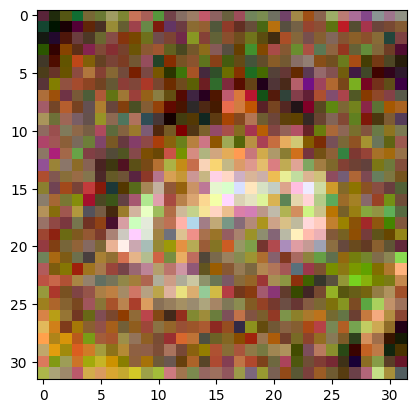

In [60]:
plt.imshow(x_train_noise[0],vmin=0,vmax=1)

In [61]:
# ENTRENAMIENTO
model.fit(x_train_noise, x_train,
                epochs=10,
                batch_size=32,
                shuffle=True,
                validation_data=(x_test, x_test))

Epoch 1/10
1563/1563 [==============================] - 52s 26ms/step - loss: 0.0201 - val_loss: 0.0039
Epoch 2/10
1563/1563 [==============================] - 41s 26ms/step - loss: 0.0087 - val_loss: 0.0034
Epoch 3/10
1563/1563 [==============================] - 37s 24ms/step - loss: 0.0078 - val_loss: 0.0026
Epoch 4/10
1563/1563 [==============================] - 33s 21ms/step - loss: 0.0075 - val_loss: 0.0024
Epoch 5/10
1563/1563 [==============================] - 39s 25ms/step - loss: 0.0072 - val_loss: 0.0024
Epoch 6/10
1563/1563 [==============================] - 35s 22ms/step - loss: 0.0071 - val_loss: 0.0019
Epoch 7/10
1563/1563 [==============================] - 34s 22ms/step - loss: 0.0071 - val_loss: 0.0021
Epoch 8/10
1563/1563 [==============================] - 37s 24ms/step - loss: 0.0070 - val_loss: 0.0022
Epoch 9/10
1563/1563 [==============================] - 38s 24ms/step - loss: 0.0070 - val_loss: 0.0031
Epoch 10/10
1563/1563 [==============================] - 39s 25m

In [62]:
# TEST
x_test_noise = x_test + 0.1*np.random.randn(*x_test.shape)

decoded_imgs = model.predict(x_test_noise)

313/313 [==============================] - 2s 5ms/step


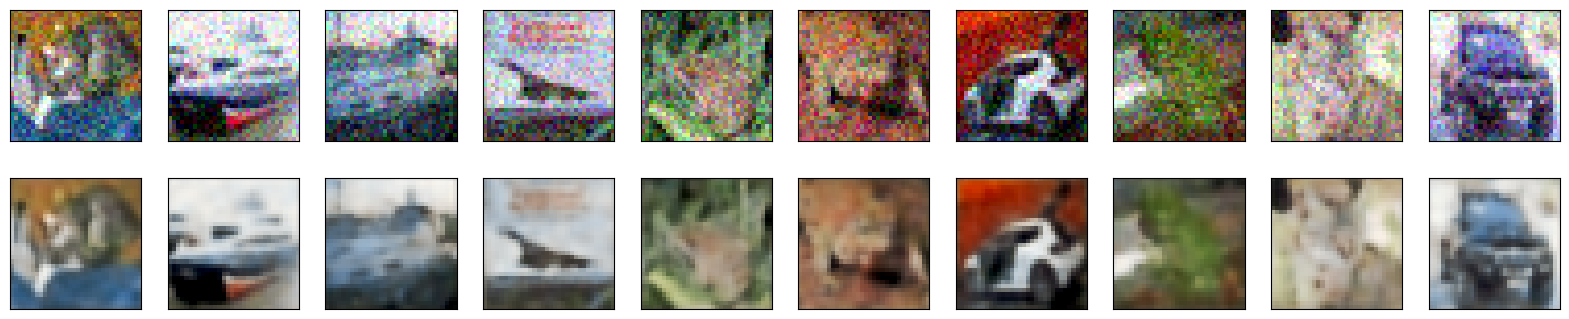

In [63]:
import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # display original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test_noise[i],vmin=0,vmax=1)

    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # display reconstruccion
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i],vmin=0,vmax=1)

    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()